# Train a simple regression model locally

The goal of this notebook is illustrate training a simple regression model with `sklearn` on the local machine.
This script

* loads `../data/Student_Performance.csv`
* splits it into training and test sets
* fits linear regression
* validates the performance in a graph

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [4]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


TODO do preprocessing here

In [8]:
X = df[["Hours Studied", "Previous Scores", "Sleep Hours", "Sample Question Papers Practiced"]]
y = df[["Performance Index"]]
print(X.head())
print(y.head())

   Hours Studied  Previous Scores  Sleep Hours  \
0              7               99            9   
1              4               82            4   
2              8               51            7   
3              5               52            5   
4              7               75            8   

   Sample Question Papers Practiced  
0                                 1  
1                                 2  
2                                 2  
3                                 2  
4                                 5  
   Performance Index
0               91.0
1               65.0
2               45.0
3               36.0
4               66.0


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)


In [10]:
lin_reg = LinearRegression().fit(X_train, y_train)


In [12]:
y_hat = lin_reg.predict(X_test)

print(f"MSE: {mean_squared_error(y_test, y_hat):.3f}")
print(f"R2 {r2_score(y_test, y_hat):.3f}")

MSE: 4.380
R2 0.988


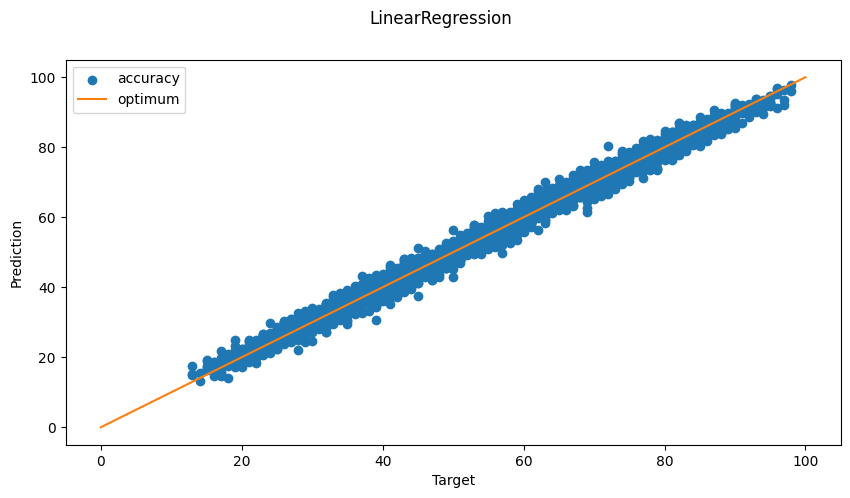

In [36]:
fig, ax = plt.subplots(figsize=(10, 5))

# ax.scatter(y_test, y_hat, label="accuracy")
ax.scatter(y_test, y_hat, label="accuracy")
ax.plot([0, 100], [0, 100], '-', color="tab:orange", label="optimum")

ax.set(xlabel="Target", ylabel="Prediction", )
ax.legend()
fig.suptitle("LinearRegression")
plt.show()